# Plot scientific interest for one pathogen–antibiotic pair

This notebook uses saved SI when the pair is available. Otherwise, its recovery helper searches the cached screened counts, candidate-year PMID lists, candidate pair-PMID links, and cached screening decisions. It rebuilds pair counts when possible, refits the pooled SI baseline for that pair, and reports counts found at each stage. The result is exploratory and does not change canonical outputs.

If only raw candidate mentions remain, `PAIR_ALLOW_CANDIDATE_PROXY` can still produce a clearly marked candidate-only figure. Its residual is not an AMR scientific-interest estimate.

Change `PATHOGEN` and `ANTIBIOTIC` in the selection cell.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.si import build_si_analysis_paths, recompute_pair_si_from_available_sources
from amr.si.core import plot_yearly_si_pair

PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)
ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level", "antibiotic")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANALYSIS_LEVEL)
SI_PATH = SI_PATHS["yearly_si"]
PATHOGEN_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT) / "single_pair_si_plots"

if not SI_PATH.exists():
    raise FileNotFoundError(f"Missing reference SI dataset {SI_PATH}. Run notebook 05_model_scientific_interest.ipynb first.")
si_df = pd.read_parquet(SI_PATH)
pathogen_background_df = pd.read_parquet(PATHOGEN_BACKGROUND_PATH)
antibiotic_background_df = pd.read_parquet(ANTIBIOTIC_BACKGROUND_PATH)
print(f"Loaded {len(si_df):,} reference SI rows from {SI_PATH}")


Loaded 15,806 reference SI rows from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet


In [2]:
# Edit these two values to plot another pair.
PATHOGEN = "Shigella dysenteriae"
ANTIBIOTIC = "Trimethoprim"

# If the selected pair is missing or too sparse in saved SI, recover it from cached
# upstream tables. Optional overrides relax only this pair's screening decision.
RECOMPUTE_PAIR_IF_MISSING = True
PAIR_RECOMPUTE_MIN_AMR_PUBLICATION_COUNT = 1.0
PAIR_SYSTEM1_PROBABILITY_THRESHOLD = None
PAIR_LLM_INCLUDE_DECISIONS = None
PAIR_ALLOW_CANDIDATE_PROXY = True

def _saved_label(value, column):
    matches = [
        candidate for candidate in si_df[column].dropna().astype(str).unique()
        if candidate.casefold() == value.casefold()
    ]
    return matches[0] if matches else value

PATHOGEN = _saved_label(PATHOGEN, "pathogen")
ANTIBIOTIC = _saved_label(ANTIBIOTIC, "antibiotic")
pair_mask = (
    si_df["pathogen"].astype(str).str.casefold().eq(PATHOGEN.casefold())
    & si_df["antibiotic"].astype(str).str.casefold().eq(ANTIBIOTIC.casefold())
)
pair_df = si_df.loc[pair_mask].sort_values("year").copy()
configured_min_count = float(cfg(PIPELINE_CONFIG, "si.min_amr_pair_publication_count"))
configured_min_years = int(cfg(PIPELINE_CONFIG, "si.min_num_years_with_valid_counts"))
fit_start_year = int(cfg(PIPELINE_CONFIG, "si.fit_start_year"))
fit_end_year = int(cfg(PIPELINE_CONFIG, "si.curve_fit_end_year"))
valid_years = pair_df.loc[
    pair_df["year"].between(fit_start_year, fit_end_year)
    & pair_df["count_for_model"].notna(), "year"
].nunique() if not pair_df.empty else 0

RECOMPUTED_PAIR_SI = False
if RECOMPUTE_PAIR_IF_MISSING and (pair_df.empty or valid_years < configured_min_years):
    recovery = recompute_pair_si_from_available_sources(
        si_reference_df=si_df,
        pathogen=PATHOGEN,
        antibiotic=ANTIBIOTIC,
        pipeline_config=PIPELINE_CONFIG,
        project_root=PROJECT_ROOT,
        pathogen_background_df=pathogen_background_df,
        antibiotic_background_df=antibiotic_background_df,
        min_amr_pair_publication_count=PAIR_RECOMPUTE_MIN_AMR_PUBLICATION_COUNT,
        system1_probability_threshold=PAIR_SYSTEM1_PROBABILITY_THRESHOLD,
        llm_include_decisions=PAIR_LLM_INCLUDE_DECISIONS,
        allow_candidate_proxy=PAIR_ALLOW_CANDIDATE_PROXY,
    )
    display(recovery["availability_by_year"])
    if recovery["pair_si_df"].empty:
        raise ValueError(recovery["message"])
    recomputed_pair_df = recovery["pair_si_df"]
    PATHOGEN = str(recomputed_pair_df.iloc[0]["pathogen"])
    ANTIBIOTIC = str(recomputed_pair_df.iloc[0]["antibiotic"])
    pair_mask = (si_df["pathogen"].eq(PATHOGEN) & si_df["antibiotic"].eq(ANTIBIOTIC))
    si_plot_df = pd.concat([si_df.loc[~pair_mask], recomputed_pair_df], ignore_index=True)
    pair_df = recomputed_pair_df.sort_values("year").copy()
    RECOMPUTED_PAIR_SI = True
    plot_min_count = PAIR_RECOMPUTE_MIN_AMR_PUBLICATION_COUNT
    PAIR_DATA_LABEL = recovery["data_label"]
    print(f"Recovered from: {recovery['source']} ({recovery['candidate_source']})")
    print(f"Interpretation: {recovery['data_interpretation']}")
else:
    si_plot_df = si_df
    plot_min_count = configured_min_count
    PAIR_DATA_LABEL = "AMR pair"
    print(f"Using saved SI for {PATHOGEN} — {ANTIBIOTIC}; yearly rows: {len(pair_df)}")

display(pair_df[["year", "count", "count_for_model", "SI"]].reset_index(drop=True))


,year,candidate_count,stored_screened_count,recomputed_screened_count
0,2000,2,0.0,<NA>
1,2003,2,1.0,<NA>
2,2005,2,1.0,<NA>
3,2006,3,2.0,<NA>
4,2007,1,1.0,<NA>
5,2008,2,1.0,<NA>
6,2010,1,1.0,<NA>
7,2012,2,2.0,<NA>
8,2014,1,0.0,<NA>
9,2015,1,1.0,<NA>


Recovered from: stored yearly_amr_screened_pairs.parquet (candidate_amr_pair_year_counts.parquet)
Interpretation: screened_amr


,year,count,count_for_model,SI
0,2003,1,1.0,0.025359
1,2005,1,1.0,-0.023953
2,2006,2,2.0,0.185604
3,2007,1,1.0,-0.019695
4,2008,1,1.0,-0.028226
5,2010,1,1.0,-0.042488
6,2012,2,2.0,0.137844
7,2015,1,1.0,-0.077539
8,2018,1,1.0,-0.101754
9,2019,1,1.0,-0.089247


Saved plot to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/single_pair_si_plots/Shigella_dysenteriae__Trimethoprim.pdf
Fit: 2000–2025; forecast extension: 5 years; valid training years: 13; SI mode: screened_amr


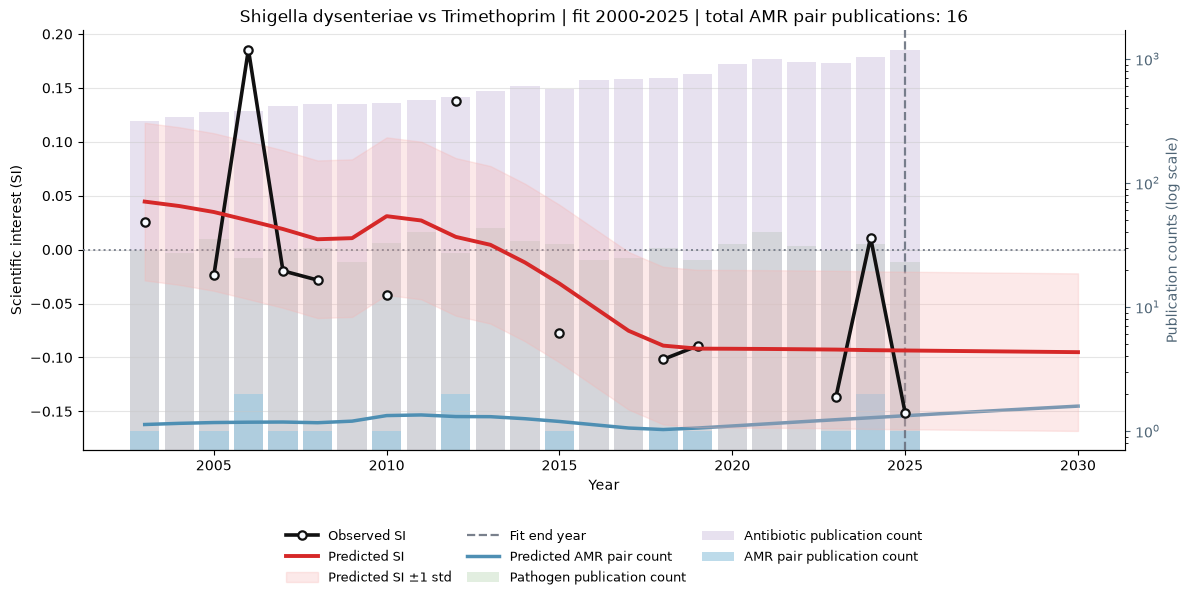

In [3]:
FIT_START_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_start_year"))
FIT_END_YEAR = int(cfg(PIPELINE_CONFIG, "si.curve_fit_end_year"))
NUM_FUTURE_YEARS = int(cfg(PIPELINE_CONFIG, "si.num_future_years"))
MIN_NUM_YEARS_WITH_VALID_COUNTS = int(cfg(PIPELINE_CONFIG, "si.min_num_years_with_valid_counts"))
if RECOMPUTED_PAIR_SI:
    available_years = pair_df.loc[
        pair_df["year"].between(FIT_START_YEAR, FIT_END_YEAR) & pair_df["count_for_model"].notna(), "year"
    ].nunique()
    if available_years == 0:
        FIT_START_YEAR = int(pair_df["year"].min())
        FIT_END_YEAR = int(pair_df["year"].max())
        available_years = pair_df["year"].nunique()
    MIN_NUM_YEARS_WITH_VALID_COUNTS = max(1, min(MIN_NUM_YEARS_WITH_VALID_COUNTS, available_years))
LOESS_FRAC = float(cfg(PIPELINE_CONFIG, "si.loess_frac"))
LOESS_DEGREE = int(cfg(PIPELINE_CONFIG, "si.loess_degree"))
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = bool(cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero"))

plot_result = plot_yearly_si_pair(
    si_df=si_plot_df,
    pathogen=PATHOGEN,
    antibiotic=ANTIBIOTIC,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_additional_years=NUM_FUTURE_YEARS,
    loess_frac=LOESS_FRAC,
    loess_degree=LOESS_DEGREE,
    tail_damping_years=TAIL_DAMPING_YEARS,
    min_amr_pair_publication_count=plot_min_count,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    pathogen_background_df=pathogen_background_df,
    antibiotic_background_df=antibiotic_background_df,
    pair_count_label=PAIR_DATA_LABEL,
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
def _plot_slug(value):
    return str(value).strip().replace("/", "_").replace("\\", "_").replace(" ", "_").replace(":", "_")

output_path = OUTPUT_DIR / f"{_plot_slug(PATHOGEN)}__{_plot_slug(ANTIBIOTIC)}.pdf"
if RECOMPUTED_PAIR_SI and PAIR_DATA_LABEL == "candidate pair":
    plot_result["ax_si"].set_ylabel("Candidate-proxy residual (not validated SI)")
    plot_result["ax_si"].set_title("UNSCREENED CANDIDATE PROXY — NOT AMR-VALIDATED\n" + plot_result["ax_si"].get_title())
plot_result["figure"].savefig(output_path, bbox_inches="tight")
print(f"Saved plot to {output_path}")
print(
    f"Fit: {FIT_START_YEAR}–{FIT_END_YEAR}; forecast extension: {NUM_FUTURE_YEARS} years; "
    f"valid training years: {plot_result['train_df']['year'].nunique()}; "
    f"SI mode: {recovery['data_interpretation'] if RECOMPUTED_PAIR_SI else 'saved canonical data'}"
)
display(plot_result["figure"])
import matplotlib.pyplot as plt
plt.close(plot_result["figure"])
